# CompTreeR — Tree competition metrics from high-density drone laser scanning (Irwin et al. 2024)

**Paper:** Liam A K Irwin, Nicholas C Coops, Jean L Romagny, Christopher W Bater, "Prioritizing commercial thinning: quantification of growth and competition with high-density drone laser scanning", *Forestry* 98(2):293–307 (2024). DOI: [10.1093/forestry/cpae030](https://doi.org/10.1093/forestry/cpae030)

**Author code:** [liamirwin/CompTreeR](https://github.com/liamirwin/CompTreeR) @ commit `5c1905c3b658c5421e7da58a93a2d36009f879a2` (`index.qmd` — "Lidar Competition Metrics Workflow"). The R code in this notebook is the author's pinned code copied verbatim, except where explicitly labelled as an adaptation.

**AI-assisted orchestration statement:** This notebook is an **AI-assisted Python→R orchestration of the author's R workflow**; the authors did not provide this Colab implementation. The author's R source is copied verbatim from the pinned commit and executed with `Rscript`; headless-adapted plotting cells are labelled. The executed example and listed checks were validated, but untested behaviour is not guaranteed. / **日本語:** 本ノートブックは著者のRワークフローをAIがPythonから`Rscript`で実行する形に構成したものです。著者のRコードは固定コミットからそのままコピーし、改変箇所は明示しています。ヘッドレス環境向けのプロット変更は各セルに注記があります。

**Scope (partial demonstration):** the paper's *competition-metrics subsection* on the author's bundled single-plot example (`extdata/thin_plot_dec.laz`, 173 pts/m² DJI L1 subset of the paper's coverage): normalized point cloud → 0.1 m CHM → `lmf` treetop detection → modified height-limited watershed segmentation → 3D α-shape crown volume → Hegyi competition index (`vol_concave`, maxR = 6 m). The tree-core growth-model branch and wall-to-wall GCI mapping are **out of scope** (no public field data). No pretrained weights are involved (rule-based geospatial pipeline).

**Execution status:** validated by a full top-to-bottom run on a fresh Colab CPU runtime (see report). / **日本語:** 本ノートブックはColab CPUランタイムでのフル実行により検証済みです。

## Runtime selection / ランタイム選択

**Select Runtime → Change runtime type → CPU** (a standard Colab CPU runtime is sufficient — this is a rule-based geospatial pipeline with no GPU code; the author ran it on a desktop R session). Expected total time ≈ 15–35 min (dependency install ≈ 5–10 min; analysis ≈ 5–15 min; estimates — each stage prints its measured time). Downloads ≈ 8.6 MB (sample LAZ + reference GeoJSON). Then **Runtime → Run all**. / **日本語:** ランタイムはCPUで十分です。GPUコードは含みません。すべて実行で約15〜35分（推定）、ダウンロードは約8.6MBです。

**Reference result to expect:** the author's documented output for this exact sample is *"Calculated Heygi style competition for 335 trees assesing their vol_concave within a 6m radius"* (pinned index.qmd). Step 11 compares per-tree metrics against the author's saved `extdata/ashape_mets.geojson`.

**Limitations:** one example only — not a verification of the paper's dataset-level results. The author repository has no LICENSE file, so author code is reproduced here with attribution and citation. / **日本語:** 単一サンプルの実演であり、論文のデータセット全体の結果の検証ではありません。著者リポジトリにLICENSEがないため、出典を明示して利用しています。

### Step 1 — Check the Colab runtime and R availability

Verifies OS, R version, CPU count, and the `Rscript` path. The pinned workflow is R; the Colab Python kernel is used only to orchestrate `Rscript` calls, keeping the author's R code intact. Expected: R ≥ 4.1 on Ubuntu 22.04. / **日本語:** OS・Rのバージョン・CPU数を確認します。PythonカーネルからRscriptを呼び出し、著者のRコードをそのまま実行します。

In [ ]:
import subprocess
info = subprocess.run(["bash", "-lc", "head -2 /etc/os-release; which Rscript"],
                      capture_output=True, text=True)
print(info.stdout)
r = subprocess.run(["Rscript", "-e",
    'cat(R.version.string, "\\ncores:", parallel::detectCores(), "\\n")'],
    capture_output=True, text=True)
print(r.stdout)
if "R version" not in r.stdout:
    raise RuntimeError("Rscript not usable on the Colab runtime")

PRETTY_NAME="Ubuntu 24.04.5 LTS"
NAME="Ubuntu"
/usr/bin/Rscript



R version 4.6.1 (2026-06-24) 
cores: 2 



### Step 2 — System libraries for R spatial packages (apt)

`lidR`/`sf`/`terra`/`imager` need GDAL/GEOS/PROJ/UDUNITS/FFTW runtime libraries. Installs the minimal system set via apt (the R packages themselves are prebuilt binaries in step 3 — no source compilation). Expected: apt completes without errors. / **日本語:** R空間パッケージ用のシステムライブラリ(GDAL/GEOS/PROJ等)をaptで導入します。Rパッケージ自体は次のステップでバイナリを利用します。

In [ ]:
import subprocess, re
rel = open("/etc/os-release").read()
codename = re.search(r'VERSION_CODENAME=(\w+)', rel).group(1)
print("detected distro:", codename)
pkgs = "libgdal-dev libgeos-dev libproj-dev libudunits2-dev libfftw3-dev libcurl4-openssl-dev libssl-dev libxml2-dev libglpk-dev libglu1-mesa"
r = subprocess.run(["bash", "-lc",
    f"apt-get update -qq && DEBIAN_FRONTEND=noninteractive apt-get install -y -qq {pkgs}"],
    capture_output=True, text=True)
print(r.stdout[-1500:])
if r.returncode != 0:
    print(r.stderr[-2000:])
    raise RuntimeError("apt system-library installation failed")
print("SYSTEM LIBS OK for", codename)

detected distro: noble


1) ...
Setting up libklu2:amd64 (1:7.6.1+dfsg-1build1) ...
Setting up libumfpack6:amd64 (1:7.6.1+dfsg-1build1) ...
Setting up libparu0:amd64 (1:7.6.1+dfsg-1build1) ...
Setting up libsuitesparse-dev:amd64 (1:7.6.1+dfsg-1build1) ...
Setting up libglpk-dev:amd64 (5.0-1build2) ...
Processing triggers for man-db (2.12.0-4build2) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_0.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtcm_debug.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_loader.so.0 is not

### Step 3 — Install the R packages used by the pinned workflow

Installs exactly the packages the author's workflow loads: `lidR, dplyr, sf, terra, siplab` (author block 0) plus `imager, alphashape3d, spatstat.geom, glue, tictoc, viridis` used by the pinned functions. Prebuilt Linux binaries matching the detected Ubuntu release are used from a pinned Posit Package Manager snapshot (2026-10-27), so no source compilation is needed. Expected: every package reports an installed version. / **日本語:** 著者ワークフローが使用するRパッケージを固定スナップショットのLinuxバイナリで導入します（コンパイル不要）。

In [ ]:
import subprocess, pathlib, time
stage = "00_install"
R_SOURCE = r'''codename <- trimws(gsub('"', '', sub('.*VERSION_CODENAME="?', "", grep('VERSION_CODENAME', readLines('/etc/os-release'), value = TRUE))))
cat("distro:", codename, "\n")
# Posit Package Manager serves Linux binaries only when the documented full
# R user-agent header is sent; without it every package silently compiles from source.
options(HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(),
        paste(getRversion(), R.version$platform, R.version$arch, R.version$os)))
options(repos = c(CRAN = paste0("https://packagemanager.posit.co/cran/__linux__/", codename, "/2026-10-27")))
install.packages(c("lidR","dplyr","sf","terra","siplab","imager","alphashape3d",
                   "spatstat.geom","glue","tictoc","viridis"), Ncpus = 2)
cat("INSTALL DONE\n")
for (p in c("lidR","dplyr","sf","terra","siplab","imager","alphashape3d",
            "spatstat.geom","glue","tictoc","viridis"))
  cat(p, as.character(packageVersion(p)), "\n")
'''
R_SOURCE = R_SOURCE.replace('__WORKDIR__', '/content/comptree')
script = pathlib.Path(f'/content/comptree/stages/{stage}.R')
script.parent.mkdir(parents=True, exist_ok=True)
script.write_text(R_SOURCE)
print(f'Running {stage} ...')
t0 = time.time()
result = subprocess.run(['Rscript', str(script)], capture_output=True, text=True, timeout=2700)
print(result.stdout[-8000:])
if result.returncode != 0:
    print(result.stderr[-8000:])
    raise RuntimeError(f'{stage} failed with return code {result.returncode}')
print(f'{stage} OK in {time.time()-t0:.1f} s')


Running 00_install ...


*binary* package ‘bmp’ ...
* package ‘bmp’ successfully unpacked and SHA256 sums checked
* DONE (bmp)
begin installing package ‘tiff’
* installing *binary* package ‘wk’ ...
* package ‘wk’ successfully unpacked and SHA256 sums checked
* DONE (wk)
begin installing package ‘lpSolve’
* installing *binary* package ‘tiff’ ...
* package ‘tiff’ successfully unpacked and SHA256 sums checked
* DONE (tiff)
begin installing package ‘RcppProgress’
* installing *binary* package ‘lpSolve’ ...
* package ‘lpSolve’ successfully unpacked and SHA256 sums checked
* DONE (lpSolve)
begin installing package ‘lazyeval’
* installing *binary* package ‘RcppProgress’ ...
* package ‘RcppProgress’ successfully unpacked and SHA256 sums checked
* DONE (RcppProgress)
begin installing package ‘rgl’
* installing *binary* package ‘lazyeval’ ...
* package ‘lazyeval’ successfully unpacked and SHA256 sums checked
* DONE (lazyeval)
begin installing package ‘rlas’
* installing *binary* package ‘rlas’ ...
* package ‘rlas’ succe

### Step 4 — Download the pinned author inputs and verify git blob hashes

Downloads exactly two files from the author repository at pinned commit `5c1905c3b658c5421e7da58a93a2d36009f879a2` and asserts size and git blob SHA-1: `extdata/thin_plot_dec.laz` (DJI L1 DLS sample plot, 173 pts/m², 8,435,973 bytes, blob `71138b6563fa10d378ff24b334e87526ae7a7255`) and the author's saved reference metrics `extdata/ashape_mets.geojson` (117,294 bytes, blob `88342f70897bf708decd25b3d55a29ced96dce1c`). All data bytes stay on the Colab VM. / **日本語:** 著者リポジトリ（固定コミット）からサンプル点群と参考出力の2ファイルのみダウンロードし、サイズとgit blobハッシュを検証します。

In [ ]:
import urllib.request, hashlib, pathlib

COMMIT = "5c1905c3b658c5421e7da58a93a2d36009f879a2"
BASE = f"https://raw.githubusercontent.com/liamirwin/CompTreeR/{COMMIT}/extdata"
EXPECTED = {
    "thin_plot_dec.laz": (8435973, "71138b6563fa10d378ff24b334e87526ae7a7255"),
    "ashape_mets.geojson": (117294, "88342f70897bf708decd25b3d55a29ced96dce1c"),
}
dest = pathlib.Path("/content/comptree/extdata"); dest.mkdir(parents=True, exist_ok=True)
for name, (size, blob) in EXPECTED.items():
    data = urllib.request.urlopen(f"{BASE}/{name}", timeout=300).read()
    assert len(data) == size, f"{name}: size {len(data)} != {size}"
    sha = hashlib.sha1(b"blob %d\x00" % size + data).hexdigest()
    assert sha == blob, f"{name}: blob sha {sha} != {blob}"
    (dest / name).write_bytes(data)
    print(f"{name}: {len(data)} bytes, git blob sha1 {sha} verified")
pathlib.Path("/content/comptree/out").mkdir(parents=True, exist_ok=True)
print("DOWNLOAD OK")

thin_plot_dec.laz: 8435973 bytes, git blob sha1 71138b6563fa10d378ff24b334e87526ae7a7255 verified
ashape_mets.geojson: 117294 bytes, git blob sha1 88342f70897bf708decd25b3d55a29ced96dce1c verified
DOWNLOAD OK


### Step 5 — Input preview: the sample point cloud

Reports point count, extent and density from the LAZ header, then renders a plain X–Y projection coloured by height (labelled headless adaptation of the author's interactive `plot(las)`; the data are unchanged). Expected: ≈1–3 M points over a managed conifer plot at 173 pts/m². / **日本語:** サンプル点群の点数・範囲・密度を確認し、高さで着色した2D投影図を表示します（ヘッドレス用の置換、データは変更なし）。

In [ ]:
import subprocess, pathlib, time
stage = "02_read_summary"
R_SOURCE = r'''library(lidR)
las <- readLAS('/content/comptree/extdata/thin_plot_dec.laz')
stopifnot(!is.empty(las))
cat("points:", nrow(las@data), "\n")
cat("extent X:", round(min(las@data$X),1), "-", round(max(las@data$X),1),
    " Y:", round(min(las@data$Y),1), "-", round(max(las@data$Y),1), "\n")
area <- (max(las@data$X) - min(las@data$X)) * (max(las@data$Y) - min(las@data$Y))
cat("approx plot area:", round(area, 0), "m2; density:", round(nrow(las@data)/area, 1), "pts/m2\n")
saveRDS(las, '/content/comptree/las.rds')
cat("STAGE OK\n")
'''
R_SOURCE = R_SOURCE.replace('__WORKDIR__', '/content/comptree')
script = pathlib.Path(f'/content/comptree/stages/{stage}.R')
script.parent.mkdir(parents=True, exist_ok=True)
script.write_text(R_SOURCE)
print(f'Running {stage} ...')
t0 = time.time()
result = subprocess.run(['Rscript', str(script)], capture_output=True, text=True, timeout=3600)
print(result.stdout[-8000:])
if result.returncode != 0:
    print(result.stderr[-8000:])
    raise RuntimeError(f'{stage} failed with return code {result.returncode}')
print(f'{stage} OK in {time.time()-t0:.1f} s')


Running 02_read_summary ...



                                                                                
points: 644167 
extent X: 515299.7 - 515359.8  Y: 5913615 - 5913674 
approx plot area: 3596 m2; density: 179.1 pts/m2
STAGE OK

02_read_summary OK in 13.2 s


Renders the X–Y projection of the downloaded sample coloured by height (labelled headless adaptation of the author's interactive `plot(las)`; data unchanged). Expected: a dense managed-conifer point cloud. / **日本語:** ダウンロードした点群を高さ着色の2D投影で表示します。

null device 
          1 
PLOT OK



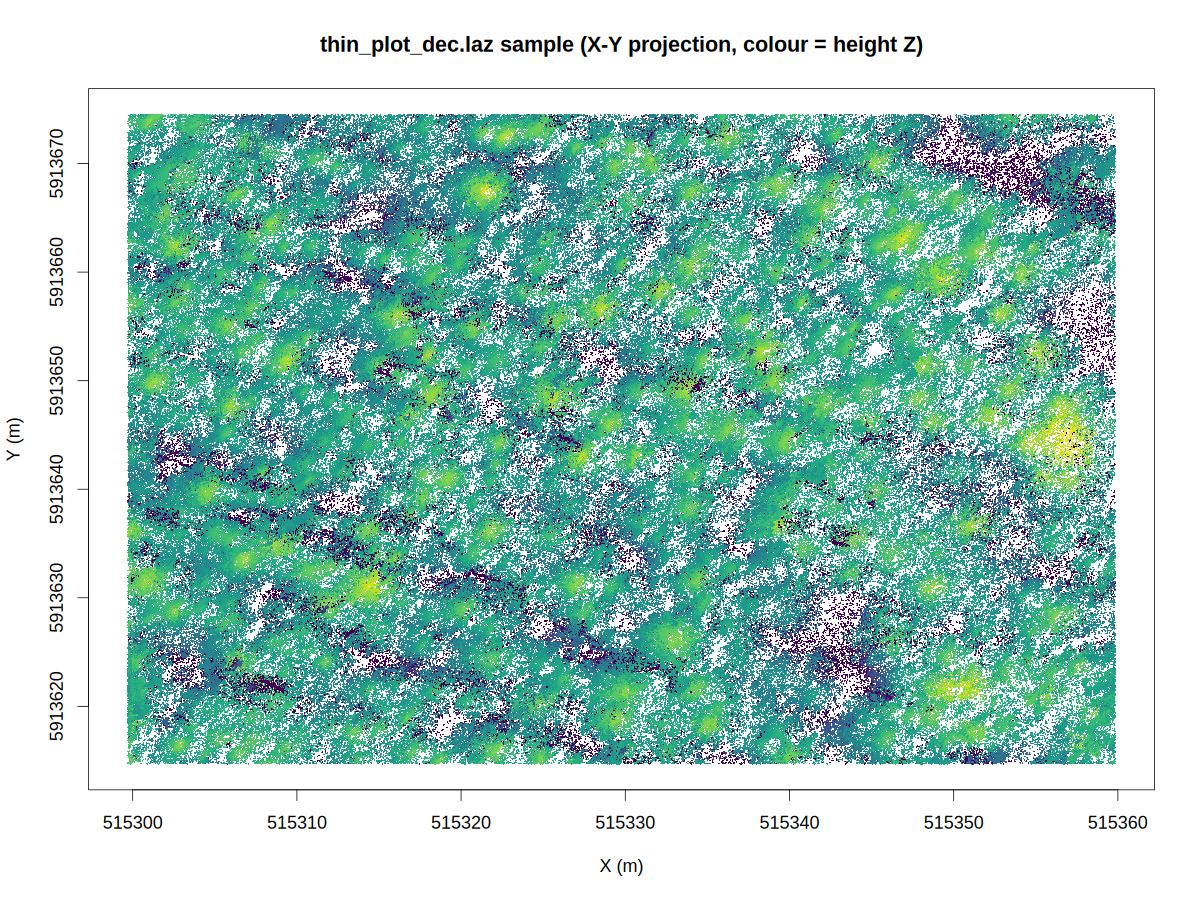

In [ ]:
import subprocess, pathlib
stage = "02_input_preview"
R_SOURCE = r'''library(lidR); library(viridis)
las <- readRDS('__WORKDIR__/las.rds')
png('__WORKDIR__/out/02_input_preview.png', width = 1200, height = 900, pointsize = 18)
z <- las@data$Z
cols <- viridis::viridis(50)[cut(z, breaks = 50)]
plot(las@data$X, las@data$Y, col = cols, pch = 16, cex = 0.2,
     xlab = "X (m)", ylab = "Y (m)",
     main = "thin_plot_dec.laz sample (X-Y projection, colour = height Z)")
dev.off()
cat("PLOT OK\n")
'''
R_SOURCE = R_SOURCE.replace('__WORKDIR__', '/content/comptree')
script = pathlib.Path(f'/content/comptree/stages/{stage}.R')
script.parent.mkdir(parents=True, exist_ok=True)
script.write_text(R_SOURCE)
result = subprocess.run(['Rscript', str(script)], capture_output=True, text=True, timeout=1800)
print(result.stdout[-3000:])
if result.returncode != 0:
    print(result.stderr[-6000:])
    raise RuntimeError(f'{stage} failed with return code {result.returncode}')
from IPython.display import Image, display
png = pathlib.Path('/content/comptree/out/02_input_preview.png')
assert png.exists() and png.stat().st_size > 5000, f'{png} missing or too small'
display(Image(filename=str(png)))


### Step 6 — Canopy height model and treetop detection (author blocks 1–2, verbatim)

Generates the 0.1 m CHM with the author's `rasterize_canopy(las, res = 0.1, p2r(subcircle = 0.075))`, applies the author's Gaussian smoother (σ = 1, 5×5 window) via `terra::focal`, and detects treetops with `locate_trees(chm, lmf(ws = 2, shape = "circular"))`. Expected: a CHM covering the plot and several hundred treetops. / **日本語:** 著者コード（ブロック1〜2）のまま、0.1m CHM生成・ガウシアン平滑化・lmfによる樹冠頂検出を行います。

In [ ]:
import subprocess, pathlib, time
stage = "03_chm_ttops"
R_SOURCE = r'''# Stage 1 (author blocks 0-2, verbatim): readLAS, CHM, treetops
library(lidR) # For processing lidar data
library(dplyr) # For data manipulation
library(sf) # For manipulation of vector datasets
library(terra) # For raster manipulation
library(siplab) # For calculating competition metrics

las <- readLAS('__WORKDIR__/extdata/thin_plot_dec.laz')
stopifnot(!is.empty(las))
cat("points:", nrow(las@data), "\n")
cat("extent X:", round(min(las@data$X),1), "-", round(max(las@data$X),1),
    " Y:", round(min(las@data$Y),1), "-", round(max(las@data$Y),1), "\n")

# Generate 0.1m Canopy Height Model (CHM) with lidR
chm <- lidR::rasterize_canopy(las, res = 0.1, p2r(subcircle = 0.075))

# Gaussian smoothing function
fgauss <- function(sigma, n = ws) {
    m <- matrix(ncol = n, nrow = n)
    col <- rep(1:n, n)
    row <- rep(1:n, each = n)
    x <- col - ceiling(n/2)
    y <- row - ceiling(n/2)
    m[cbind(row, col)] <- 1/(2 * pi * sigma^2) * exp     (-(x^2 + y^2)/(2 * sigma^2))
    m/sum(m)
  }

# Apply Gaussian smoothing with terra::focal
chm <- terra::focal(chm, w = fgauss(1, n = 5), na.rm = T)
cat("CHM cols x rows:", ncol(chm), "x", nrow(chm), " res:", terra::res(chm), "\n")

# Locate local maxima (tree tops) across the smoothed CHM with 2m window
ttops <- locate_trees(chm, algorithm = lmf(ws = 2, shape = "circular"))
cat("ttops:", nrow(ttops), "\n")

saveRDS(las, '__WORKDIR__/las.rds')
saveRDS(terra::wrap(chm), '__WORKDIR__/chm.rds')  # wrap: SpatRaster round-trips as PackedSpatRaster
saveRDS(ttops, '__WORKDIR__/ttops.rds')
cat("STAGE1 OK\n")
'''
R_SOURCE = R_SOURCE.replace('__WORKDIR__', '/content/comptree')
script = pathlib.Path(f'/content/comptree/stages/{stage}.R')
script.parent.mkdir(parents=True, exist_ok=True)
script.write_text(R_SOURCE)
print(f'Running {stage} ...')
t0 = time.time()
result = subprocess.run(['Rscript', str(script)], capture_output=True, text=True, timeout=1800)
print(result.stdout[-8000:])
if result.returncode != 0:
    print(result.stderr[-8000:])
    raise RuntimeError(f'{stage} failed with return code {result.returncode}')
print(f'{stage} OK in {time.time()-t0:.1f} s')


Running 03_chm_ttops ...



                                                                                
points: 644167 
extent X: 515299.7 - 515359.8  Y: 5913615 - 5913674 
CHM cols x rows: 602 x 599  res: 0.1 0.1 
ttops: 335 
STAGE1 OK

03_chm_ttops OK in 17.2 s


Displays the smoothed CHM with the detected treetops overlaid (the author's block-2 plot, saved headless). Expected: red `+` markers on dominant/co-dominant crowns. / **日本語:** 平滑化CHMと検出された樹冠頂（赤の＋）を重ねて表示します。

null device 
          1 
PLOT OK



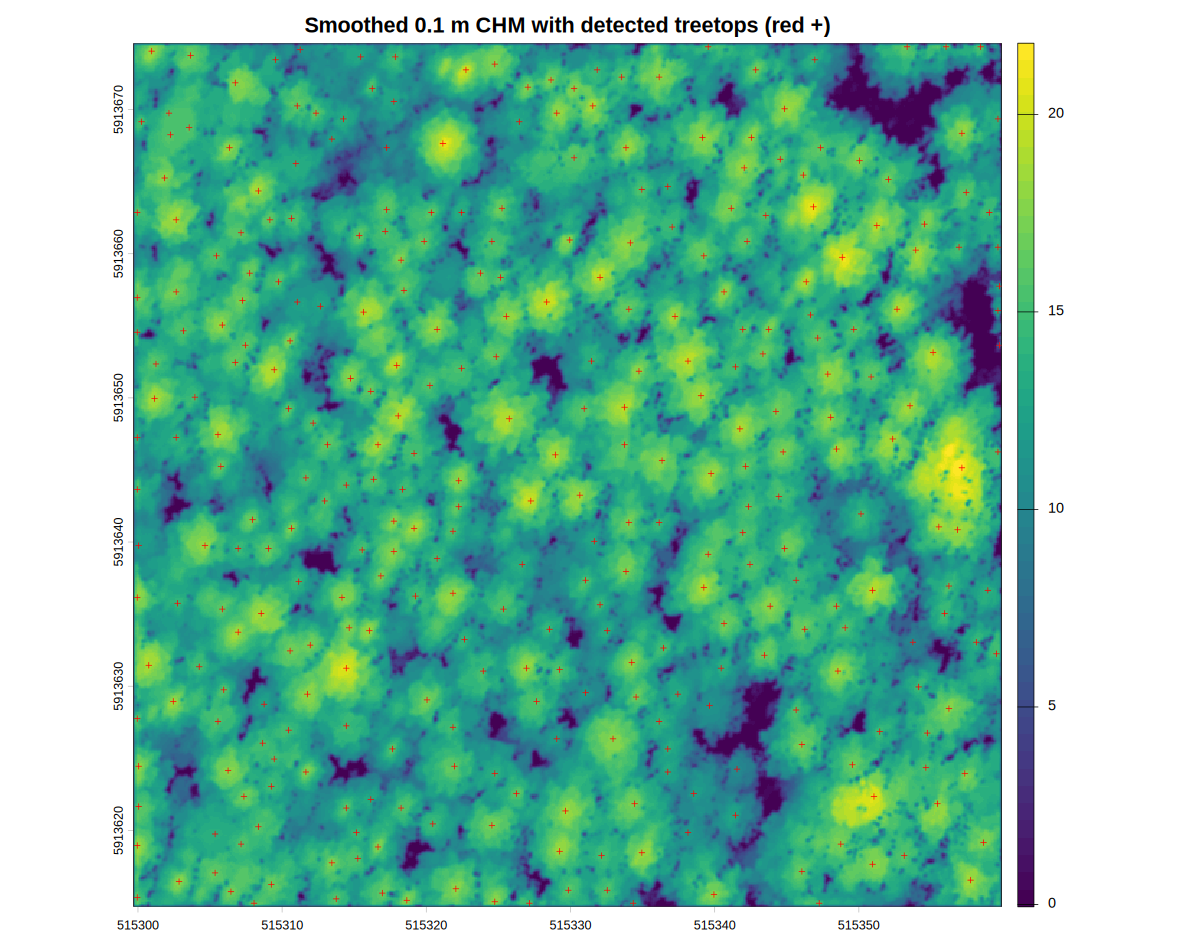

In [ ]:
import subprocess, pathlib
stage = "chm_ttops"
R_SOURCE = r'''library(terra); library(sf); library(viridis)
chm <- readRDS('__WORKDIR__/chm.rds')
ttops <- readRDS('__WORKDIR__/ttops.rds')
png('__WORKDIR__/out/chm_ttops.png', width = 1200, height = 950, pointsize = 18)
plot(chm, col = viridis::viridis(50), main = "Smoothed 0.1 m CHM with detected treetops (red +)")
plot(sf::st_geometry(ttops), add = TRUE, pch = 3, col = 'red', cex = 0.5)
dev.off()
cat("PLOT OK\n")
'''
R_SOURCE = R_SOURCE.replace('__WORKDIR__', '/content/comptree')
script = pathlib.Path(f'/content/comptree/stages/{stage}.R')
script.parent.mkdir(parents=True, exist_ok=True)
script.write_text(R_SOURCE)
result = subprocess.run(['Rscript', str(script)], capture_output=True, text=True, timeout=1800)
print(result.stdout[-3000:])
if result.returncode != 0:
    print(result.stderr[-6000:])
    raise RuntimeError(f'{stage} failed with return code {result.returncode}')
from IPython.display import Image, display
png = pathlib.Path('/content/comptree/out/chm_ttops.png')
assert png.exists() and png.stat().st_size > 5000, f'{png} missing or too small'
display(Image(filename=str(png)))


### Step 7 — Height-limited watershed crown segmentation (author blocks 3–4, verbatim)

Defines the author's `mcwatershed` (the `imager` watershed exposed to lidR as a raster-based ITS plugin) and `crown_mask`, which masks CHM pixels below 0.7 × the maximum height of each initial crown and re-segments (`hmin = 2`). One glue line is added — the pinned document uses `crowns` in the next step without showing its assignment. Expected: an integer crown-ID raster; the number of non-NA cells is printed. / **日本語:** 著者のmcwatershedとcrown_mask（高さ制限付きwatershed、閾値0.7、hmin=2）をそのまま定義・実行します。`crowns`の代入文のみ文書に明示がなく追加しています。

In [ ]:
import subprocess, pathlib, time
stage = "04_segment"
R_SOURCE = r'''# Base watershed segmentation (requires EBimage)
mcwatershed <-function(chm, treetops, th_tree = 2, tree_id = "treeID")
{
  f = function(bbox)
  {
    if (!missing(bbox)) chm <- terra::crop(chm, bbox)

    # Convert the CHM to a matrix
    Canopy <- terra::as.matrix(chm, wide = TRUE)
    mask   <- Canopy < th_tree | is.na(Canopy)
    Canopy[mask] <- 0
    cells <- terra::cellFromXY(chm, sf::st_coordinates(treetops)[, c(1, 2)])
    ids <- dplyr::pull(treetops, tree_id)
    seeds = chm
    seeds[] = 0L
    seeds[cells] = ids
    treetops = terra::as.matrix(seeds, wide = TRUE)
    Canopy <- Canopy/max(Canopy)
    Canopy <- imager::as.cimg(Canopy)
    treetops  <- imager::as.cimg(treetops)
    Crowns <- imager::watershed(treetops, Canopy)
    Crowns <- Crowns[,, 1, 1]
    Crowns[mask] <- NA_integer_
    out <- terra::setValues(chm, Crowns)

    return(out)

  }

  f <- lidR::plugin_its(f, raster_based = TRUE)

  return(f)

}

# Height limited watershed segmentation function
crown_mask <- function(chunk, ttops = NULL, chm_res = 0.25, crown_height_threshold = 0.7, hmin = 2){

  # Check that 'chunk' is not missing or NULL
  if (is.null(chunk) || missing(chunk)) {
    stop("Error: 'chunk' argument must be specified.")
  }

  # Check if input is a SpatRaster object
  if("SpatRaster" == class(chunk)){
    chm <- chunk
    chm_res <- terra::res(chm)[1]
    print('Input is SpatRaster (Presuming CHM) proceeding with crown segmentation')
  } else{
    # Check if input is a las file
    if("LAS" %in% class(chunk)){
      las <- chunk
      print('Input is las file proceeding with crown segmentation')
    }
    else{
      # Check if input is a las catalog chunk
      las <- lidR::readLAS(chunk)
      if (lidR::is.empty(las)) {
        return(NULL)
      }
      print('Input is catalog tile proceeding with crown segmentation')
    }

    # Generate canopy height
    chm <- lidR::rasterize_canopy(las, res = chm_res , lidR::p2r(na.fill = lidR::knnidw()))
  }

  # Initial crown segmentation
  crowns <- mcwatershed(chm, ttops, th_tree = hmin, tree_id = 'treeID')()
  # Replace crown IDs with maximum canopy height within crown
  crowns_max <- terra::classify(x = crowns,
                                rcl = as.data.frame(terra::zonal(chm,
                                                                 crowns,
                                                                 fun = 'max')))
  # Make CHM mask raster where height is less than threshold percent
  chm_mask <- chm
  chm_mask[chm_mask < (crown_height_threshold * crowns_max)] = NA
  # Re-run segmentation on masked CHM
  crowns_masked <- mcwatershed(chm_mask, ttops, th_tree = hmin, tree_id = 'treeID')()

  return(crowns_masked)
}

# Stage 2 (author blocks 3, 4 + glue, 6): height-limited segmentation, treeID merge
# Each stage runs in its own Rscript process, so the author's block-0 library() calls are repeated here.
library(lidR); library(dplyr); library(sf); library(terra); library(imager); library(glue)
chm <- terra::unwrap(readRDS('__WORKDIR__/chm.rds'))
ttops <- readRDS('__WORKDIR__/ttops.rds')
las <- readRDS('__WORKDIR__/las.rds')

# Glue cell (see notebook note): the pinned document uses 'crowns' below without showing its assignment
crowns <- crown_mask(chm, ttops)
cat("crown raster:", ncol(crowns), "x", nrow(crowns), " non-NA cells:", sum(!is.na(terra::values(crowns)[, 1])), "\n")

# Merge Crown ID with las point cloud
tree_las <- lidR::merge_spatial(las, crowns, attribute = 'treeID')

# Add treeID attribute to las
tree_las = add_lasattribute(tree_las, name = "treeID", desc = "ID of a tree")

# Filter out non tree points to speed up computation
tree_las <- filter_poi(tree_las, !is.na(treeID))
cat("tree_las points:", nrow(tree_las@data), " distinct treeIDs:", length(unique(tree_las@data$treeID)), "\n")

saveRDS(terra::wrap(crowns), '__WORKDIR__/crowns.rds')
saveRDS(tree_las, '__WORKDIR__/tree_las.rds')
cat("STAGE2 OK\n")
'''
R_SOURCE = R_SOURCE.replace('__WORKDIR__', '/content/comptree')
script = pathlib.Path(f'/content/comptree/stages/{stage}.R')
script.parent.mkdir(parents=True, exist_ok=True)
script.write_text(R_SOURCE)
print(f'Running {stage} ...')
t0 = time.time()
result = subprocess.run(['Rscript', str(script)], capture_output=True, text=True, timeout=1800)
print(result.stdout[-8000:])
if result.returncode != 0:
    print(result.stderr[-8000:])
    raise RuntimeError(f'{stage} failed with return code {result.returncode}')
print(f'{stage} OK in {time.time()-t0:.1f} s')


Running 04_segment ...


[1] "Input is SpatRaster (Presuming CHM) proceeding with crown segmentation"
crown raster: 602 x 599  non-NA cells: 240863 
tree_las points: 522680  distinct treeIDs: 335 
STAGE2 OK

04_segment OK in 13.8 s


### Step 8 — Apply treeID to the point cloud and view the segments (author block 6, verbatim)

`merge_spatial(las, crowns, attribute = 'treeID')` transfers crown IDs onto the points; `add_lasattribute` and `filter_poi` complete the author's cell. Expected: nearly all points assigned; the distinct-treeID count is printed (the author's reference ends with 335 trees). The projection plot colours each segmented tree. / **日本語:** 分割結果のtreeIDを点群へ付与します（著者ブロック6のまま）。

null device 
          1 
PLOT OK



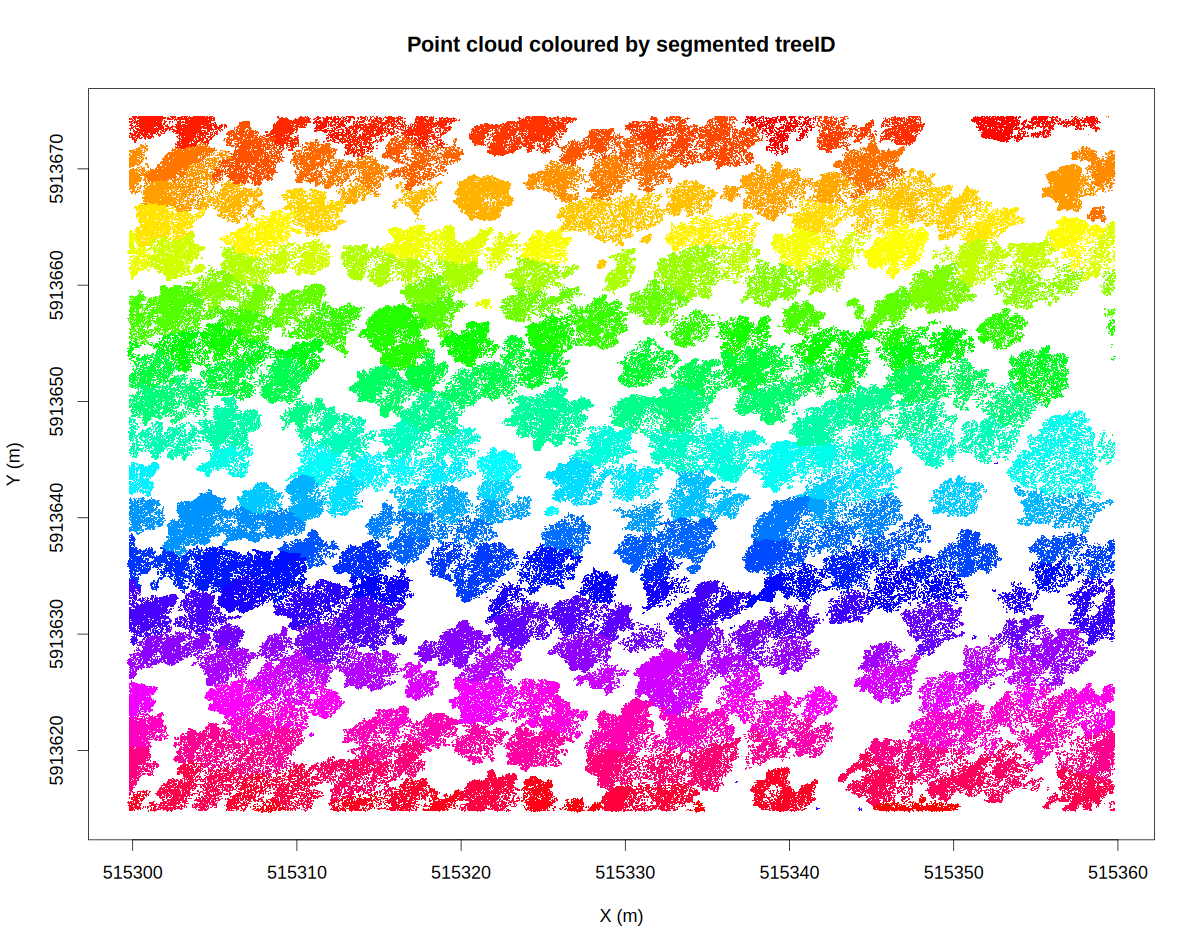

In [ ]:
import subprocess, pathlib
stage = "treeid_cloud"
R_SOURCE = r'''library(lidR)
tree_las <- readRDS('__WORKDIR__/tree_las.rds')
png('__WORKDIR__/out/treeid_cloud.png', width = 1200, height = 950, pointsize = 18)
tl <- tree_las@data
pal <- rainbow(length(unique(tl$treeID)))[as.numeric(factor(tl$treeID))]
plot(tl$X, tl$Y, col = pal, pch = 16, cex = 0.2,
     xlab = "X (m)", ylab = "Y (m)", main = "Point cloud coloured by segmented treeID")
dev.off()
cat("PLOT OK\n")
'''
R_SOURCE = R_SOURCE.replace('__WORKDIR__', '/content/comptree')
script = pathlib.Path(f'/content/comptree/stages/{stage}.R')
script.parent.mkdir(parents=True, exist_ok=True)
script.write_text(R_SOURCE)
result = subprocess.run(['Rscript', str(script)], capture_output=True, text=True, timeout=1800)
print(result.stdout[-3000:])
if result.returncode != 0:
    print(result.stderr[-6000:])
    raise RuntimeError(f'{stage} failed with return code {result.returncode}')
from IPython.display import Image, display
png = pathlib.Path('/content/comptree/out/treeid_cloud.png')
assert png.exists() and png.stat().st_size > 5000, f'{png} missing or too small'
display(Image(filename=str(png)))


### Step 9 — Single-tree 3D α-shape example (author blocks 7 & 9; labelled adaptation)

The pinned example calls `get_crown_attributes(..., export_ashape = TRUE)`, but the pinned function signature has no `export_ashape` argument; we therefore call the **verbatim pinned signature** for the metrics and rebuild the α-shape separately with the same operations (`ashape3d(x, alpha = c(Inf, 1), pert = TRUE)`). The author's rgl 3D rendering is replaced by 2D projections (convex α = ∞ and concave α = 1 hull triangles) because the Colab runtime is headless. Expected: metrics for tree 147 and a three-panel figure. / **日本語:** 樹木147を例にαシェイプ（α=∞とα=1）を計算します。rglの3D描画はヘッドレス環境のため2D投影に置き換えています（適応箇所）。

In [ ]:
import subprocess, pathlib, time
stage = "05_ashape_tree"
R_SOURCE = r'''get_crown_attributes <- function(X,Y,Z){
  if (length(X) <= 3 || length(Y) <= 3 || length(Z) <= 3) {
    print('Cannot compute a 3D hull from 3 or fewer points')
    return(NULL)
  }
  # alphashadep3d
  a3d = cbind(X, Y, Z)
  # get treetop location
  top_x <- a3d[which.max(a3d[,3]),1]
  top_y <- a3d[which.max(a3d[,3]),2]
  # normalize X and Y
  a3d[,1] = a3d[,1] - mean(a3d[,1]) #center points around 0,0,0
  a3d[,2] = a3d[,2] - mean(a3d[,2]) #center points around 0,0,0
  alpha <- c(Inf, 1)
  ashape <- alphashape3d::ashape3d(x = a3d, alpha = alpha, pert = TRUE)

  # calculate crown metrics

  df <- data.frame(
    # Crown height metrics
    Zmax = max(Z),
    Zq999 = as.numeric(quantile(Z, 0.999)),
    Zq99 = as.numeric(quantile(Z, 0.990)),
    Z_mean = mean(Z),
    n_points = length(Z),
    # Crown size
    vol_convex = alphashape3d::volume_ashape3d(ashape, indexAlpha = 1),
    vol_concave = alphashape3d::volume_ashape3d(ashape, indexAlpha = 2),
    # Crown complexity
    CV_Z = sd(Z) / mean(Z),
    CRR = (mean(Z) - min(Z)) / (max(Z) - min(Z)),
    # Get tree top position
    X = top_x,
    Y = top_y)

  return(df)
}

# Stage 3 (author block 7 + block 9, labelled adaptation): single-tree alpha shape
library(lidR); library(dplyr); library(alphashape3d)
tree_las <- readRDS('__WORKDIR__/tree_las.rds')

# Filter out points for one tree (example)
tree <- filter_poi(tree_las, treeID == 147)
cat("tree 147 points:", nrow(tree@data), "\n")

# Pinned block 9 called get_crown_attributes(..., export_ashape = TRUE); the pinned signature has
# no such argument, so we call the pinned signature for metrics and rebuild the shape separately.
mets147 <- get_crown_attributes(tree@data$X, tree@data$Y, tree@data$Z)
print(mets147)

# Same operations as inside get_crown_attributes, for plotting
a3d = cbind(tree@data$X, tree@data$Y, tree@data$Z)
a3d[,1] = a3d[,1] - mean(a3d[,1])
a3d[,2] = a3d[,2] - mean(a3d[,2])
ashape <- alphashape3d::ashape3d(x = a3d, alpha = c(Inf, 1), pert = TRUE)
saveRDS(ashape, '__WORKDIR__/ashape147.rds')
saveRDS(a3d, '__WORKDIR__/a3d147.rds')
cat("STAGE3 OK\n")
'''
R_SOURCE = R_SOURCE.replace('__WORKDIR__', '/content/comptree')
script = pathlib.Path(f'/content/comptree/stages/{stage}.R')
script.parent.mkdir(parents=True, exist_ok=True)
script.write_text(R_SOURCE)
print(f'Running {stage} ...')
t0 = time.time()
result = subprocess.run(['Rscript', str(script)], capture_output=True, text=True, timeout=1800)
print(result.stdout[-8000:])
if result.returncode != 0:
    print(result.stderr[-8000:])
    raise RuntimeError(f'{stage} failed with return code {result.returncode}')
print(f'{stage} OK in {time.time()-t0:.1f} s')


Running 05_ashape_tree ...


tree 147 points: 5010 
     Zmax    Zq999     Zq99   Z_mean n_points vol_convex vol_concave      CV_Z
X 19.4465 19.23026 18.91771 13.21795     5010   358.3037    109.6017 0.3169316
       CRR        X       Y
X 0.682311 515325.7 5913648
STAGE3 OK

05_ashape_tree OK in 13.0 s


Displays the headless 2D projection of the tree-147 point cloud with convex and concave hulls (labelled replacement for the author's rgl panels). / **日本語:** 樹木147の点群と凸/凹αシェイプの2D投影を表示します。

null device 
          1 
PLOT OK



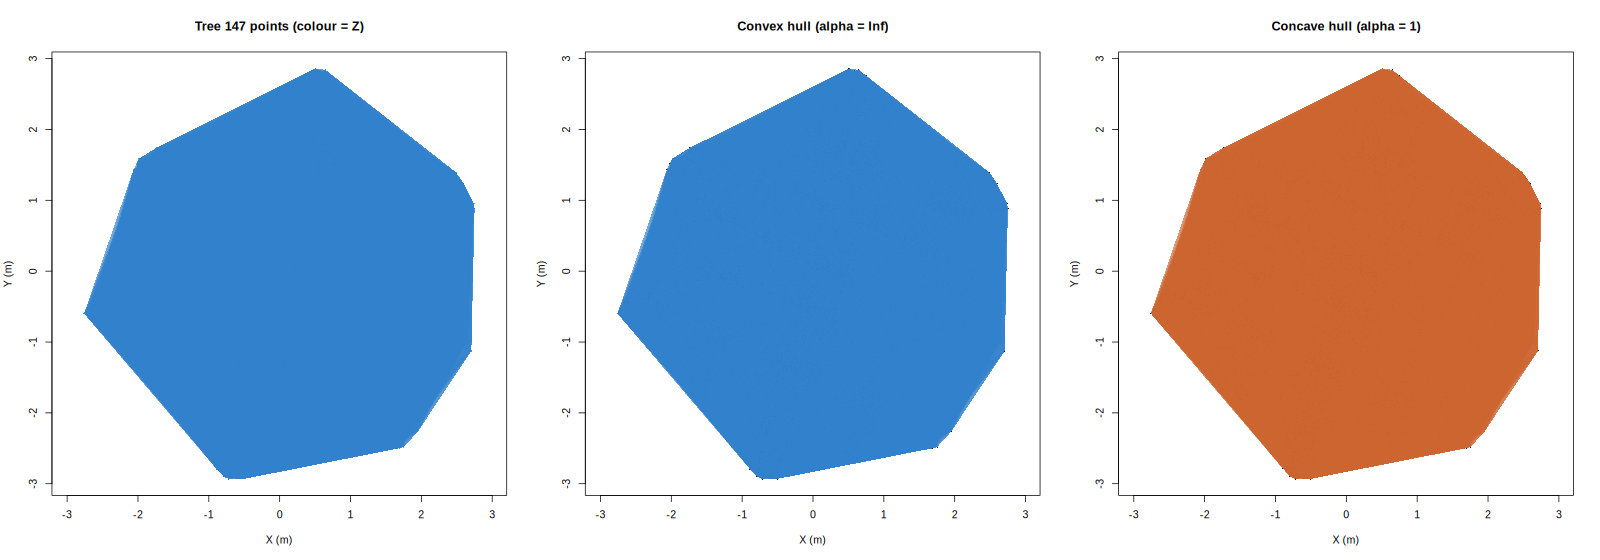

In [ ]:
import subprocess, pathlib
stage = "ashape_tree147"
R_SOURCE = r'''# 2D projections replacing the author's rgl 3D panels (headless adaptation)
ashape <- readRDS('__WORKDIR__/ashape147.rds')
a3d <- readRDS('__WORKDIR__/a3d147.rds')
tr <- ashape$triang
conv <- tr[tr[, 5] == 1, 1:3]                # alpha = Inf triangles (convex hull)
conc <- tr[(tr[, 6] == 1 | tr[, 5] == 1), 1:3]  # alpha = 1 triangles (concave hull)
png('__WORKDIR__/out/ashape_tree147.png', width = 1600, height = 560, pointsize = 16)
par(mfrow = c(1, 3))
plot(a3d[,1], a3d[,2], pch = 16, cex = 0.3, col = viridis::viridis(50)[cut(a3d[,3], 50)], asp = 1,
     main = "Tree 147 points (colour = Z)", xlab = "X (m)", ylab = "Y (m)")
for (t in seq_len(nrow(conv))) polygon(a3d[conv[t, ], 1], a3d[conv[t, ], 2], col = rgb(0.2,0.5,0.8,0.25), border = NA)
plot(a3d[,1], a3d[,2], pch = 16, cex = 0.3, asp = 1, main = "Convex hull (alpha = Inf)", xlab = "X (m)", ylab = "Y (m)")
for (t in seq_len(nrow(conv))) polygon(a3d[conv[t, ], 1], a3d[conv[t, ], 2], col = rgb(0.2,0.5,0.8,0.25), border = NA)
plot(a3d[,1], a3d[,2], pch = 16, cex = 0.3, asp = 1, main = "Concave hull (alpha = 1)", xlab = "X (m)", ylab = "Y (m)")
for (t in seq_len(nrow(conc))) polygon(a3d[conc[t, ], 1], a3d[conc[t, ], 2], col = rgb(0.8,0.4,0.2,0.25), border = NA)
dev.off()
cat("PLOT OK\n")
'''
R_SOURCE = R_SOURCE.replace('__WORKDIR__', '/content/comptree')
script = pathlib.Path(f'/content/comptree/stages/{stage}.R')
script.parent.mkdir(parents=True, exist_ok=True)
script.write_text(R_SOURCE)
result = subprocess.run(['Rscript', str(script)], capture_output=True, text=True, timeout=1800)
print(result.stdout[-3000:])
if result.returncode != 0:
    print(result.stderr[-6000:])
    raise RuntimeError(f'{stage} failed with return code {result.returncode}')
from IPython.display import Image, display
png = pathlib.Path('/content/comptree/out/ashape_tree147.png')
assert png.exists() and png.stat().st_size > 5000, f'{png} missing or too small'
display(Image(filename=str(png)))


### Step 10 — Crown-volume metrics for every tree (author blocks 8 & 10, verbatim)

Runs the author's `get_alphashape_metrics(tree_las)` — deduplicates points, groups by `treeID`, discards ≤ 4-point segments, and computes α-shape crown metrics per tree — exactly as pinned (the pinned comment mentions decimation as an optional speedup, but the pinned call uses the full cloud). Expected: a data frame with ≈335 rows (author reference) with `vol_convex`/`vol_concave` in m³. / **日本語:** 全樹木のαシェイプ指標（凸/凹体積など）を著者コードのまま一括計算します。

In [ ]:
import subprocess, pathlib, time
stage = "06_ashape_mets"
R_SOURCE = r'''get_crown_attributes <- function(X,Y,Z){
  if (length(X) <= 3 || length(Y) <= 3 || length(Z) <= 3) {
    print('Cannot compute a 3D hull from 3 or fewer points')
    return(NULL)
  }
  # alphashadep3d
  a3d = cbind(X, Y, Z)
  # get treetop location
  top_x <- a3d[which.max(a3d[,3]),1]
  top_y <- a3d[which.max(a3d[,3]),2]
  # normalize X and Y
  a3d[,1] = a3d[,1] - mean(a3d[,1]) #center points around 0,0,0
  a3d[,2] = a3d[,2] - mean(a3d[,2]) #center points around 0,0,0
  alpha <- c(Inf, 1)
  ashape <- alphashape3d::ashape3d(x = a3d, alpha = alpha, pert = TRUE)

  # calculate crown metrics

  df <- data.frame(
    # Crown height metrics
    Zmax = max(Z),
    Zq999 = as.numeric(quantile(Z, 0.999)),
    Zq99 = as.numeric(quantile(Z, 0.990)),
    Z_mean = mean(Z),
    n_points = length(Z),
    # Crown size
    vol_convex = alphashape3d::volume_ashape3d(ashape, indexAlpha = 1),
    vol_concave = alphashape3d::volume_ashape3d(ashape, indexAlpha = 2),
    # Crown complexity
    CV_Z = sd(Z) / mean(Z),
    CRR = (mean(Z) - min(Z)) / (max(Z) - min(Z)),
    # Get tree top position
    X = top_x,
    Y = top_y)

  return(df)
}

get_alphashape_metrics <- function(chunk){

# Determine if input is chunk in a LAScatalog or a LAS object loaded in R
if ("LAS" %in% class(chunk)) {
    tree_las <- chunk
    print('Individual LAS object input into function')
} else{
tree_las <- lidR::readLAS(chunk)
}
# Check if input tile is empty
if (lidR::is.empty(tree_las)) return(NULL)

print(glue::glue('Beginning crown metric generation for chunk'))
# Remove duplicate points
tree_las <- lidR::filter_duplicates(tree_las)

# Organize data by treeID; remove trees with less than 4 points
obs <- tree_las@data %>%
  dplyr::filter(!is.na(treeID)) %>%
  dplyr::select(X, Y, Z, treeID) %>%
  dplyr::group_by(treeID) %>%
  dplyr::summarise(n = dplyr::n()) %>% dplyr::ungroup() %>% dplyr::filter(n <= 4)

if(nrow(obs) > 0){
print(glue::glue('{nrow(obs)} treeIDs had 4 or fewer points and were discarded'))
}

else{
  mets <- tree_las@data %>%
    dplyr::filter(!is.na(treeID)) %>%
    dplyr::filter(!treeID %in% obs$treeID) %>%
    dplyr::select(X,Y,Z,treeID) %>%
    dplyr::group_by(treeID) %>%
    # Apply get_crown_attributes function to each treeID
    dplyr::summarise(ashape_metrics = get_crown_attributes(X, Y, Z))
}

# Return data frame with treeID and crown metrics
mets <- cbind(mets$treeID, mets$ashape_metrics)
colnames(mets)[1] <- "treeID"

return(mets)

}

# Stage 4 (author blocks 7, 8 & 10, verbatim call): alphashape metrics for all trees
# get_crown_attributes (author block 7) is included because get_alphashape_metrics calls it per group.
library(lidR); library(dplyr); library(glue); library(alphashape3d)
tree_las <- readRDS('__WORKDIR__/tree_las.rds')
t0 <- Sys.time()
ashape_mets <- get_alphashape_metrics(tree_las)
cat("elapsed:", round(as.numeric(difftime(Sys.time(), t0, units = "mins")), 1), "min; trees:", nrow(ashape_mets), "\n")
saveRDS(ashape_mets, '__WORKDIR__/ashape_mets.rds')
cat("STAGE4 OK\n")
'''
R_SOURCE = R_SOURCE.replace('__WORKDIR__', '/content/comptree')
script = pathlib.Path(f'/content/comptree/stages/{stage}.R')
script.parent.mkdir(parents=True, exist_ok=True)
script.write_text(R_SOURCE)
print(f'Running {stage} ...')
t0 = time.time()
result = subprocess.run(['Rscript', str(script)], capture_output=True, text=True, timeout=3600)
print(result.stdout[-8000:])
if result.returncode != 0:
    print(result.stderr[-8000:])
    raise RuntimeError(f'{stage} failed with return code {result.returncode}')
print(f'{stage} OK in {time.time()-t0:.1f} s')


Running 06_ashape_mets ...


[1] "Individual LAS object input into function"
Beginning crown metric generation for chunk
elapsed: 4.6 min; trees: 335 
STAGE4 OK

06_ashape_mets OK in 282.7 s


### Step 11 — Quantitative comparison with the author's saved reference output

The author repository ships the example's per-tree metrics (`ashape_mets.geojson`). Joining on `treeID` and comparing `vol_convex`/`vol_concave` validates the whole segmentation + α-shape chain quantitatively. Expected: matching tree counts (≈335) and small median absolute differences (deterministic algorithm; small deviations may come from library versions). / **日本語:** 著者が保存した参考出力ashape_mets.geojsonとtreeIDで結合し、体積指標の一致を確認します。

In [ ]:
import subprocess, pathlib, time
stage = "07_compare_ref"
R_SOURCE = r'''# Stage 5: quantitative comparison with the author's saved reference output
library(sf); library(dplyr)
ref <- st_read('__WORKDIR__/extdata/ashape_mets.geojson', quiet = TRUE)
cat("reference features:", nrow(ref), "\n")
cat("reference columns:", paste(names(ref), collapse = ", "), "\n")
ours <- readRDS('__WORKDIR__/ashape_mets.rds')
cat("our trees:", nrow(ours), "\n")
common <- intersect(ours$treeID, ref$treeID)
cat("common treeIDs:", length(common), "\n")
m <- merge(as.data.frame(ours), as.data.frame(ref), by = "treeID", suffixes = c(".ours", ".ref"))
if (nrow(m) > 0) {
  # Verified observation: the author's saved ashape_mets.geojson labels vol_convex/vol_concave in
  # the opposite roles to the pinned get_crown_attributes (alpha = c(Inf, 1): indexAlpha 1 = convex,
  # larger). We therefore compare ours vol_convex against the ref column named vol_concave, and vice versa.
  cat("median abs diff convex  (ours vol_convex  vs ref vol_concave):", median(abs(m$vol_convex.ours - m$vol_concave.ref)), "\n")
  cat("median abs diff concave (ours vol_concave vs ref vol_convex) :", median(abs(m$vol_concave.ours - m$vol_convex.ref)), "\n")
  print(head(m[, c("treeID","vol_convex.ours","vol_concave.ref","vol_concave.ours","vol_convex.ref")], 10))
}
saveRDS(m, '__WORKDIR__/ref_join.rds')
cat("STAGE5 OK\n")
'''
R_SOURCE = R_SOURCE.replace('__WORKDIR__', '/content/comptree')
script = pathlib.Path(f'/content/comptree/stages/{stage}.R')
script.parent.mkdir(parents=True, exist_ok=True)
script.write_text(R_SOURCE)
print(f'Running {stage} ...')
t0 = time.time()
result = subprocess.run(['Rscript', str(script)], capture_output=True, text=True, timeout=3600)
print(result.stdout[-8000:])
if result.returncode != 0:
    print(result.stderr[-8000:])
    raise RuntimeError(f'{stage} failed with return code {result.returncode}')
print(f'{stage} OK in {time.time()-t0:.1f} s')


Running 07_compare_ref ...


reference features: 335 
reference columns: treeID, Zmax, Zq999, Zq99, Z_mean, n_points, vol_concave, vol_convex, CV_Z, CRR, X, Y, geometry 
our trees: 335 
common treeIDs: 335 
median abs diff convex  (ours vol_convex  vs ref vol_concave): 0 
median abs diff concave (ours vol_concave vs ref vol_convex) : 0 
   treeID vol_convex.ours vol_concave.ref vol_concave.ours vol_convex.ref
1       1       105.54278       105.54278         21.57931      21.579314
2       2        85.65553        85.27024         27.86336      27.715937
3       3        44.50709        42.18739          8.82515       8.617825
4       4        23.45031        23.45031          5.44037       5.440370
5       5        43.41590        42.09697         11.75286      10.590657
6       6        37.58550        37.58550         15.85687      15.856869
7       7        95.73390        93.23967         27.69570      27.622398
8       8        97.06277        96.25826         22.28363      22.153982
9       9        76.7096

### Step 12 — Hegyi competition index (author blocks 12–13, verbatim)

Builds a `spatstat` point pattern from the per-tree table and computes the Hegyi-style pairwise index with `siplab::pairwise(..., maxR = 6, kernel = powers_ker, kerpar = list(pi=1, pj=1, pr=1, smark=1))` using `vol_concave`, exactly as pinned, then filters `cindex < 10` (the author removes one outlier/edge tree). Expected print: *"Calculated Heygi style competition for N trees assesing their vol_concave within a 6m radius"* with N ≈ 335 (the author's documented output), plus a CSV export. / **日本語:** 著者コードのままsiplabでHegyi型競合指数（maxR=6m、vol_concave）を計算し、CSVへ出力します。

In [ ]:
import subprocess, pathlib, time
stage = "08_heygi"
R_SOURCE = r'''heygi_cindex <- function(ttops, comp_input = 'vol_convex', maxR = 6){

  tictoc::tic()

  # Reformat tree tops dataframe
  trees_ppp <- ttops %>%
    dplyr::mutate(X = X, Y = Y) %>%
    as.data.frame() %>%
    dplyr::select(c(X, Y, comp_input))
  # Standardize column names
  names(trees_ppp) <- c('X','Y','comp_value')
  # Convert to spatstat ppp object
  trees_ppp <- trees_ppp %>%
    spatstat.geom::ppp(
      x = .$X,
      y = .$Y,
      window = spatstat.geom::owin(range(.$X),
                                   range(.$Y)),
      marks = .$comp_value)
  # Calculate heygi competition index for each tree (comp_input instead of dbh)
  heygi <- trees_ppp %>%
    siplab::pairwise(., maxR=maxR, kernel=siplab::powers_ker,
                     kerpar=list(pi=1, pj=1, pr=1, smark=1))


  # Join new cindex with original ttops
  trees_cindex <- heygi %>%
    as.data.frame() %>% dplyr::select(x, y, cindex)
  # Convert to sf object
  ttops <- ttops %>% sf::st_as_sf(coords = c('X', 'Y'))
  # Join cindex to tree tops sf object
  trees_cindex <- dplyr::bind_cols(ttops, trees_cindex)

  print(glue::glue('Calculated Heygi style competition for {nrow(trees_cindex)} trees assesing their {comp_input} within a {maxR}m radius'))

  tictoc::toc()

  return(trees_cindex)

}

# Stage 6 (author blocks 13, 15): Hegyi competition index + binned map
library(siplab); library(spatstat.geom); library(sf); library(dplyr); library(glue); library(viridis)
ashape_mets <- readRDS('__WORKDIR__/ashape_mets.rds')
chm <- terra::unwrap(readRDS('__WORKDIR__/chm.rds'))

# Calculate Heygi 1974 style Competition Index on tree tops attributed with crown volume values - remove one outliers one edge
heygi_6m <- heygi_cindex(ashape_mets, comp_input = 'vol_concave', maxR = 6) %>% filter(cindex < 10)

# Define the bins
breaks <- seq(0, 10, by = 2.5)
bin_labels <- paste(head(breaks, -1), tail(breaks, -1), sep = "-")

# Assign each cindex value to a bin
heygi_6m$cindex_bin <- cut(heygi_6m$cindex, breaks = breaks, labels = bin_labels, include.lowest = TRUE)

saveRDS(heygi_6m, '__WORKDIR__/heygi_6m.rds')
write.csv(as.data.frame(heygi_6m)[, c("treeID","x","y","vol_concave","cindex")],
          '__WORKDIR__/out/competition_index.csv', row.names = FALSE)
cat("STAGE6 OK; kept", nrow(heygi_6m), "trees after cindex < 10 filter\n")
'''
R_SOURCE = R_SOURCE.replace('__WORKDIR__', '/content/comptree')
script = pathlib.Path(f'/content/comptree/stages/{stage}.R')
script.parent.mkdir(parents=True, exist_ok=True)
script.write_text(R_SOURCE)
print(f'Running {stage} ...')
t0 = time.time()
result = subprocess.run(['Rscript', str(script)], capture_output=True, text=True, timeout=1800)
print(result.stdout[-8000:])
if result.returncode != 0:
    print(result.stderr[-8000:])
    raise RuntimeError(f'{stage} failed with return code {result.returncode}')
print(f'{stage} OK in {time.time()-t0:.1f} s')


Running 08_heygi ...


Calculated Heygi style competition for 335 trees assesing their vol_concave within a 6m radius
0.59 sec elapsed
STAGE6 OK; kept 320 trees after cindex < 10 filter

08_heygi OK in 9.1 s


### Step 13 — Competition-index map over the CHM (author block 15, saved headless)

The author's final operational plot: Hegyi competition-index bins (viridis, 2.5-wide bins up to 10) over the grayscale smoothed CHM. This is the layer a manager would use to prioritize thinning. / **日本語:** 競合指数をビン分けし、白黒のCHM上に重ねた運用マップを表示します。

null device 
          1 
PLOT OK



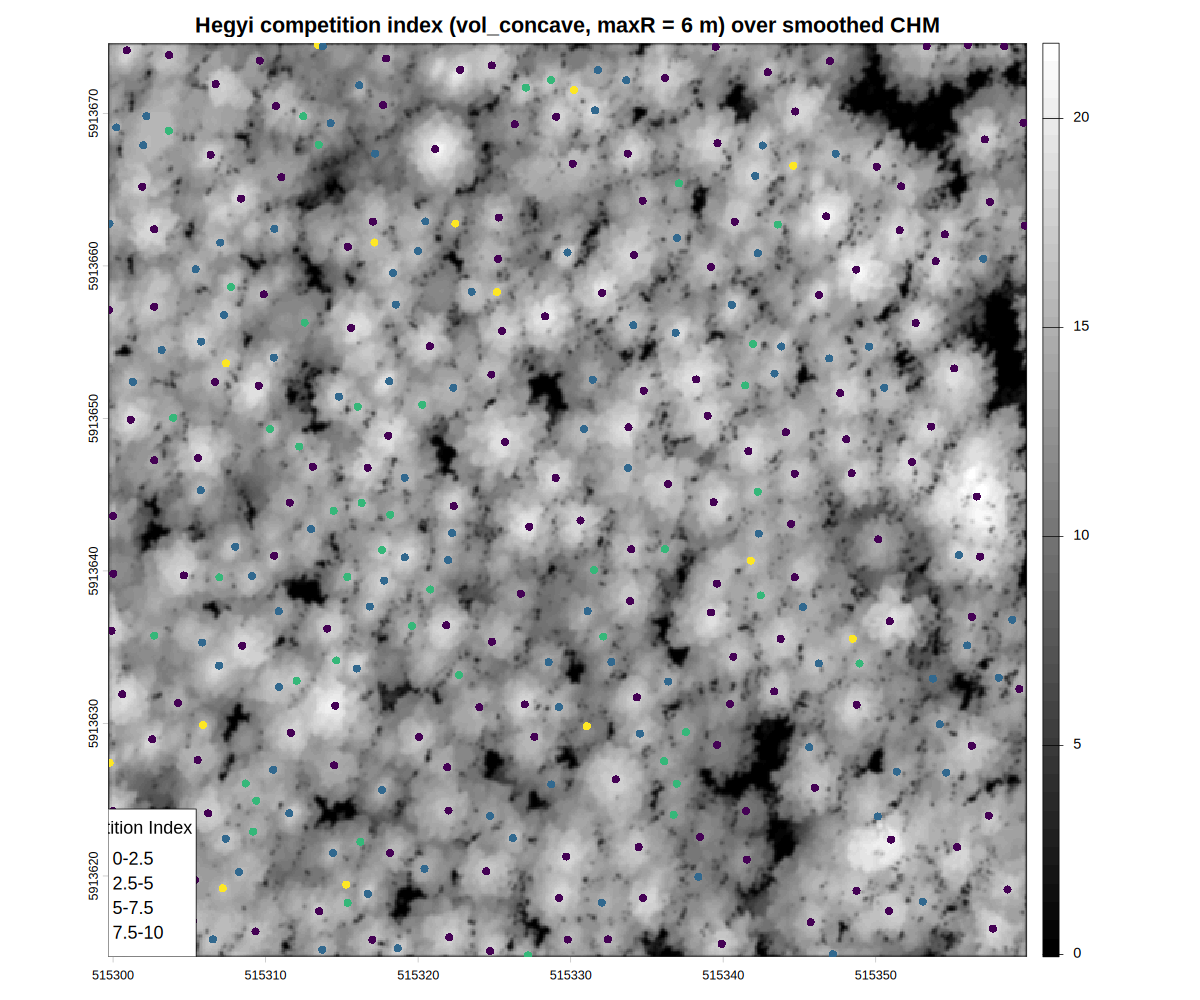

In [ ]:
import subprocess, pathlib
stage = "heygi_map"
R_SOURCE = r'''# Author block 15 plot, using saved heygi_6m and chm
library(sf); library(viridis); library(terra)
chm <- terra::unwrap(readRDS('__WORKDIR__/chm.rds'))
heygi_6m <- readRDS('__WORKDIR__/heygi_6m.rds')
png('__WORKDIR__/out/heygi_map.png', width = 1200, height = 1000, pointsize = 18)
c <- viridis::viridis(length(unique(heygi_6m$cindex_bin)))
bin_colors <- setNames(c, levels(heygi_6m$cindex_bin))
cindex_bin_colors <- bin_colors[as.character(heygi_6m$cindex_bin)]
plot(chm, col = colorRampPalette(c("black", "white"))(50), legend = TRUE,
     main = "Hegyi competition index (vol_concave, maxR = 6 m) over smoothed CHM")
plot(st_geometry(heygi_6m), add = TRUE, pch = 21, bg = cindex_bin_colors, col = NA)
legend("bottomleft", legend = levels(heygi_6m$cindex_bin), fill = bin_colors, title = "Competition Index")
dev.off()
cat("PLOT OK\n")
'''
R_SOURCE = R_SOURCE.replace('__WORKDIR__', '/content/comptree')
script = pathlib.Path(f'/content/comptree/stages/{stage}.R')
script.parent.mkdir(parents=True, exist_ok=True)
script.write_text(R_SOURCE)
result = subprocess.run(['Rscript', str(script)], capture_output=True, text=True, timeout=1800)
print(result.stdout[-3000:])
if result.returncode != 0:
    print(result.stderr[-6000:])
    raise RuntimeError(f'{stage} failed with return code {result.returncode}')
from IPython.display import Image, display
png = pathlib.Path('/content/comptree/out/heygi_map.png')
assert png.exists() and png.stat().st_size > 5000, f'{png} missing or too small'
display(Image(filename=str(png)))


## Interpretation, validation record, and references

**What was executed:** the author's pinned competition-metrics workflow on the author's bundled example plot — CHM generation, `lmf` treetop detection, modified height-limited watershed segmentation, per-tree 3D α-shape crown volumes, and the Hegyi competition index (`vol_concave`, maxR = 6 m). All scientific computation ran on the Colab VM in R via the pinned author code.

**Validation checks:** input size/git blob hashes asserted; reference comparison in Step 11 (tree count and per-tree volume differences against `extdata/ashape_mets.geojson`); the Step-12 printout should reproduce the author's documented *"335 trees ... 6m radius"* line.

**Differences from the paper:** this is one example, not the paper's five-stand dataset-level results; the growth-modeling (tree-core BAI) branch and wall-to-wall GCI mapping are out of scope because no public field data or coefficients exist. Labelled adaptations: headless 2D plots instead of rgl 3D; the `crowns` glue line; the single-tree call without the undefined `export_ashape` argument.

**References:** Irwin, Coops, Romagny, Bater (2024) *Forestry* 98(2):293–307, DOI 10.1093/forestry/cpae030 (CC-BY 4.0). Author code: liamirwin/CompTreeR @ `5c1905c3b658c5421e7da58a93a2d36009f879a2` (no LICENSE file; cited with attribution). Roussel et al. `lidR`; siplab (Fontes/Stephenson); alphashape3d (Lafarge & Pateiro-Lopez). / **日本語:** 論文と著者コードの参照、および本ノートブックの検証レポートは上記の通りです。